In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 42
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
PAL = ["#1f4e79", "#e67e22", "#27ae60", "#7d3c98", "#c0392b", "#7f8c8d"]

In [2]:
import warnings
warnings.filterwarnings('ignore')


## 2. Load and explore the data

In [3]:
df = pd.read_csv("pune_household_energy.csv")
print("Shape:", df.shape)
df.head()

Shape: (400, 10)


,household_id,area,avg_daily_kwh,morning_share,daytime_share,evening_share,night_share,weekend_ratio,summer_ratio,true_segment
0,PH001,Wakad,13.282962,0.202130,0.200137,0.459496,0.138238,1.030587,1.160998,B
1,PH002,Kondhwa,20.800000,0.165011,0.263668,0.276779,0.294543,1.174603,1.665468,C
2,PH003,Aundh,5.786468,0.224795,0.069989,0.562434,0.142782,1.200663,1.121143,A
3,PH004,Hadapsar,5.474649,0.180787,0.177572,0.397615,0.244027,1.076754,1.386878,B
4,PH005,Katraj,6.073043,0.187895,0.136032,0.456764,0.219310,1.128134,0.901979,A


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
avg_daily_kwh,400.0,12.30,6.90,2.26,7.24,11.12,14.18,47.58
morning_share,400.0,0.19,0.06,0.06,0.15,0.19,0.22,0.37
daytime_share,400.0,0.22,0.11,0.04,0.13,0.19,0.31,0.60
evening_share,400.0,0.38,0.09,0.19,0.31,0.38,0.43,0.65
night_share,400.0,0.21,0.07,0.08,0.16,0.20,0.26,0.44
weekend_ratio,400.0,1.05,0.10,0.74,1.00,1.06,1.12,1.32
summer_ratio,400.0,1.30,0.22,0.90,1.15,1.26,1.35,1.97


| Feature | Meaning |
|---|---|
| `avg_daily_kwh` | average electricity used per day (kWh) |
| `morning_share`, `daytime_share`, `evening_share`, `night_share` | fraction of daily use in 6–10 am, 10 am–6 pm, 6–11 pm, 11 pm–6 am (add up to 1) |
| `weekend_ratio` | weekend-day use ÷ weekday use |
| `summer_ratio` | summer use ÷ winter use |

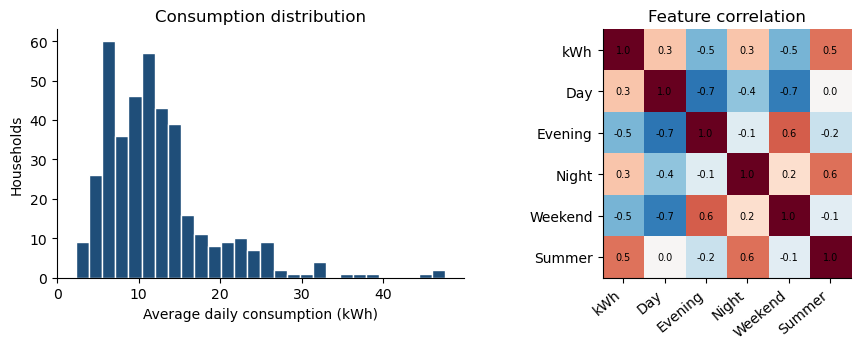

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].hist(df["avg_daily_kwh"], bins=28, color=PAL[0], edgecolor="white")
axes[0].set_xlabel("Average daily consumption (kWh)"); axes[0].set_ylabel("Households"); axes[0].set_title("Consumption distribution")
use = ["avg_daily_kwh", "daytime_share", "evening_share", "night_share", "weekend_ratio", "summer_ratio"]
corr = df[use].corr()
im = axes[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(6)); axes[1].set_yticks(range(6))
axes[1].set_xticklabels(["kWh", "Day", "Evening", "Night", "Weekend", "Summer"], rotation=40, ha="right")
axes[1].set_yticklabels(["kWh", "Day", "Evening", "Night", "Weekend", "Summer"])
for i in range(6):
    for j in range(6): axes[1].text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
axes[1].set_title("Feature correlation"); plt.tight_layout(); plt.show()

## 3. Feature scaling
Clustering uses distances, so features must be on the same scale (z-score).
The morning share is dropped because the four shares add up to 1 (it carries no extra information).

In [6]:
use = ["avg_daily_kwh", "daytime_share", "evening_share", "night_share", "weekend_ratio", "summer_ratio"]
X = StandardScaler().fit_transform(df[use])
truth = df["true_segment"].map({"A": 0, "B": 1, "C": 2, "D": 3, "X": 4}).values   # only for final checking
kwh = df["avg_daily_kwh"].values
print(X.shape)

(400, 6)


## 4. Choosing the number of clusters (k)
Three criteria: **Elbow** (inertia), **Silhouette**, and **BIC** of a Gaussian mixture.

  File "C:\Users\OM\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\OM\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\OM\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\OM\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


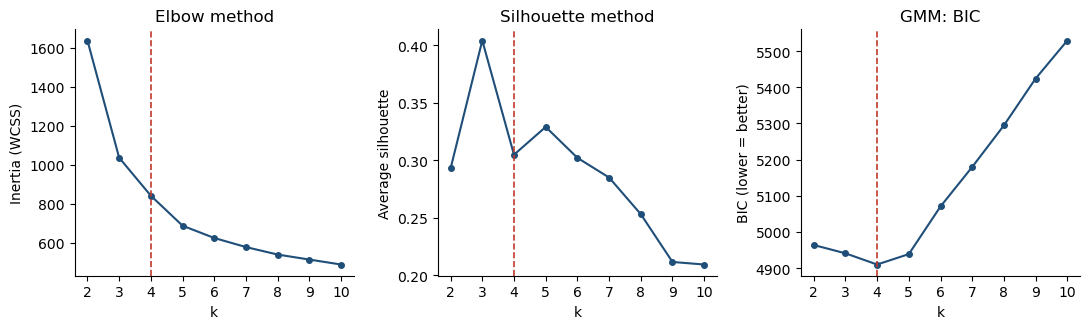

,Inertia,Silhouette,GMM BIC
k,,,
2,1637.2,0.293,4963.7
3,1036.1,0.404,4940.7
4,841.1,0.305,4909.7
5,687.2,0.329,4938.5
6,624.2,0.302,5070.3
7,577.6,0.285,5179.6
8,539.2,0.253,5294.4
9,513.5,0.211,5424.0
10,488.1,0.209,5529.1


In [7]:
ks = list(range(2, 11))
inertia, sil, bic = [], [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
    bic.append(GaussianMixture(k, covariance_type="full", n_init=3, random_state=SEED).fit(X).bic(X))

K = 4
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (y, t, yl) in zip(axes, [(inertia, "Elbow method", "Inertia (WCSS)"), (sil, "Silhouette method", "Average silhouette"), (bic, "GMM: BIC", "BIC (lower = better)")]):
    ax.plot(ks, y, "-o", color=PAL[0], ms=4); ax.axvline(K, ls="--", color=PAL[4], lw=1.2)
    ax.set_xlabel("k"); ax.set_ylabel(yl); ax.set_title(t); ax.set_xticks(ks)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"k": ks, "Inertia": np.round(inertia, 1), "Silhouette": np.round(sil, 3), "GMM BIC": np.round(bic, 1)}).set_index("k"))

**Decision:** silhouette peaks at k = 3, but the BIC is lowest at k = 4 and the elbow lies between 3 and 4. We choose **k = 4** because four groups can be described meaningfully. (The choice of k is partly a matter of judgement.)

## 5. K-Means (k = 4)

In [8]:
def order_labels(labels):
    """Renumber clusters so that cluster 0 has the lowest average kWh, 1 the next, ..."""
    ids = [i for i in np.unique(labels) if i != -1]
    order = sorted(ids, key=lambda i: kwh[labels == i].mean())
    mp = {old: new for new, old in enumerate(order)}; mp[-1] = -1
    return np.array([mp[l] for l in labels])

km = KMeans(K, n_init=20, random_state=SEED).fit(X)
lab_km = order_labels(km.labels_)
print("Silhouette:", round(silhouette_score(X, lab_km), 3),
      " Davies-Bouldin:", round(davies_bouldin_score(X, lab_km), 3),
      " Calinski-Harabasz:", round(calinski_harabasz_score(X, lab_km), 1))

Silhouette: 0.305  Davies-Bouldin: 1.118  Calinski-Harabasz: 244.7


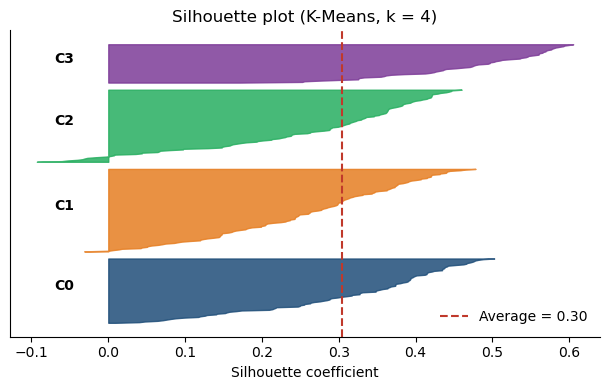

In [9]:
sil_k = silhouette_samples(X, lab_km)
fig, ax = plt.subplots(figsize=(6.2, 4))
y0 = 10
for c in range(K):
    v = np.sort(sil_k[lab_km == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=PAL[c], alpha=0.85)
    ax.text(-0.07, y0 + len(v)/2, f"C{c}", fontweight="bold"); y0 += len(v) + 10
ax.axvline(sil_k.mean(), color="#c0392b", ls="--", label=f"Average = {sil_k.mean():.2f}")
ax.set_yticks([]); ax.set_xlabel("Silhouette coefficient"); ax.legend(frameon=False, loc="lower right"); ax.set_title("Silhouette plot (K-Means, k = 4)")
plt.tight_layout(); plt.show()

### Cluster profiles – what does each group look like?

In [10]:
df["cluster"] = lab_km
FEATS = ["avg_daily_kwh", "morning_share", "daytime_share", "evening_share", "night_share", "weekend_ratio", "summer_ratio"]
prof = df.groupby("cluster")[FEATS].mean().round(2)
prof.insert(0, "households", df.groupby("cluster").size())
prof

,households,avg_daily_kwh,morning_share,daytime_share,evening_share,night_share,weekend_ratio,summer_ratio
cluster,,,,,,,,
0,100,6.32,0.21,0.11,0.48,0.19,1.16,1.12
1,128,10.03,0.20,0.20,0.38,0.22,1.06,1.25
2,112,15.25,0.17,0.38,0.29,0.16,0.95,1.27
3,60,21.58,0.14,0.17,0.36,0.33,1.07,1.74


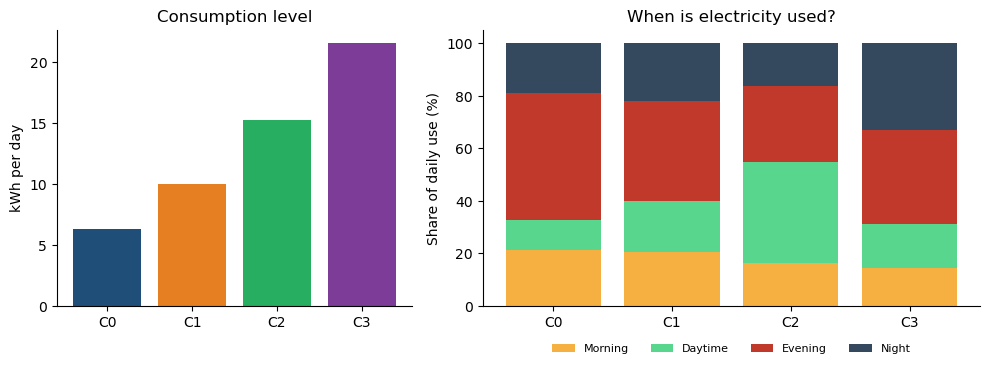

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
g = df.groupby("cluster")
axes[0].bar([f"C{c}" for c in range(K)], g["avg_daily_kwh"].mean(), color=PAL[:K]); axes[0].set_ylabel("kWh per day"); axes[0].set_title("Consumption level")
bottom = np.zeros(K)
for col, nm, colr in [("morning_share", "Morning", "#f5b041"), ("daytime_share", "Daytime", "#58d68d"), ("evening_share", "Evening", "#c0392b"), ("night_share", "Night", "#34495e")]:
    v = g[col].mean().values * 100
    axes[1].bar([f"C{c}" for c in range(K)], v, bottom=bottom, label=nm, color=colr); bottom += v
axes[1].set_ylabel("Share of daily use (%)"); axes[1].set_title("When is electricity used?")
axes[1].legend(frameon=False, ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

| Cluster | Name | Key feature |
|---|---|---|
| C0 | Low-usage evening-peak households | ~6 kWh/day, ~48 % of use in the evening |
| C1 | Moderate-usage family households | ~10 kWh/day, balanced pattern |
| C2 | Daytime-active (work-from-home) households | ~15 kWh/day, ~38 % of use in the daytime |
| C3 | High-usage AC-driven households | ~22 kWh/day, strong summer rise, high night use |

### Visualising the clusters with PCA (6-D → 2-D)

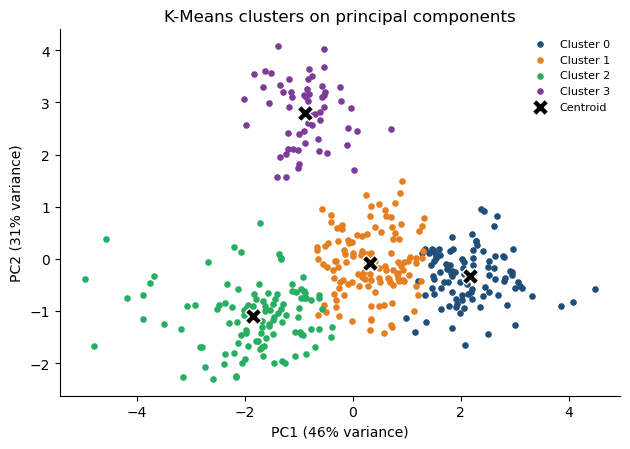

In [12]:
pca = PCA(2, random_state=SEED); P = pca.fit_transform(X)
cent = pca.transform(km.cluster_centers_)
order = sorted(range(K), key=lambda i: kwh[km.labels_ == i].mean())
plt.figure(figsize=(6.4, 4.6))
for c in range(K): plt.scatter(P[lab_km == c, 0], P[lab_km == c, 1], s=14, color=PAL[c], label=f"Cluster {c}")
plt.scatter(cent[order, 0], cent[order, 1], marker="X", s=140, color="black", edgecolor="white", label="Centroid")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
plt.legend(frameon=False, fontsize=8); plt.title("K-Means clusters on principal components"); plt.tight_layout(); plt.show()

## 6. Hierarchical clustering (agglomerative, Ward linkage)
Starts with every household as its own cluster and merges the two closest clusters step by step. The **dendrogram** records the merges; cutting it gives the clusters.

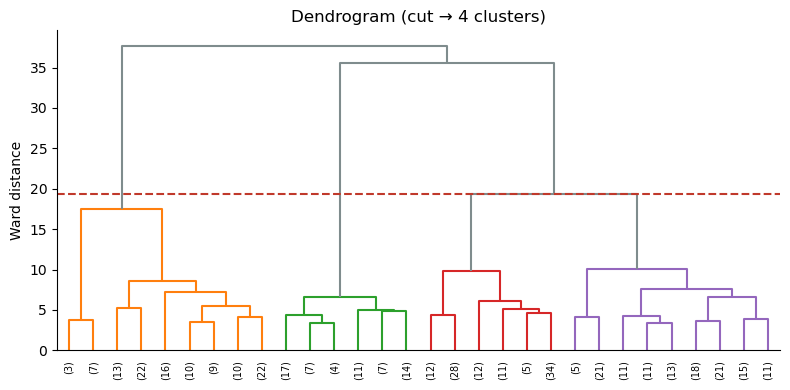

Ward  silhouette: 0.278  DBI: 1.191


In [13]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(8, 4))
cut = Z[-(K - 1), 2]
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=cut - 1e-6, above_threshold_color="#7f8c8d", leaf_rotation=90, leaf_font_size=7)
ax.axhline(cut - 1e-3, color="#c0392b", ls="--"); ax.set_ylabel("Ward distance"); ax.set_title("Dendrogram (cut → 4 clusters)")
plt.tight_layout(); plt.show()

lab_h = order_labels(AgglomerativeClustering(K, linkage="ward").fit_predict(X))
print("Ward  silhouette:", round(silhouette_score(X, lab_h), 3), " DBI:", round(davies_bouldin_score(X, lab_h), 3))

In [14]:
rows = []
for lk in ["ward", "complete", "average", "single"]:
    l = AgglomerativeClustering(K, linkage=lk).fit_predict(X)
    rows.append([lk, silhouette_score(X, l), adjusted_rand_score(truth, l), sorted(np.bincount(l).tolist(), reverse=True)])
pd.DataFrame(rows, columns=["Linkage", "Silhouette", "ARI vs hidden groups", "Cluster sizes"]).set_index("Linkage").round(3)

,Silhouette,ARI vs hidden groups,Cluster sizes
Linkage,,,
ward,0.278,0.735,"[126, 112, 102, 60]"
complete,0.324,0.506,"[243, 87, 60, 10]"
average,0.292,0.247,"[327, 60, 10, 3]"
single,0.157,0.035,"[389, 7, 3, 1]"


## 7. DBSCAN (density-based)
* **eps** = neighbourhood radius, **min_samples** = points needed for a dense region.
* Point types: *core*, *border*, *noise (outlier)*. No need to give k.
* eps is chosen from the **k-distance plot** (look for the bend).

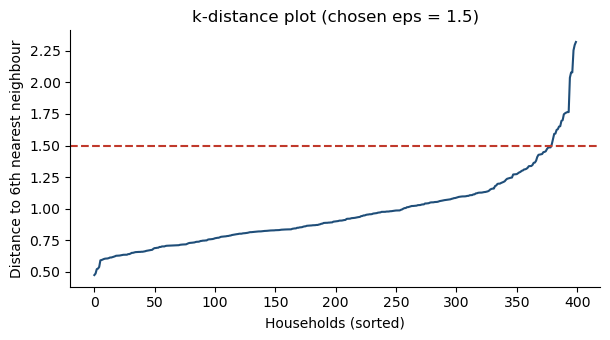

In [15]:
MIN_PTS = 6
kd = np.sort(NearestNeighbors(n_neighbors=MIN_PTS).fit(X).kneighbors(X)[0][:, -1])
plt.figure(figsize=(6.2, 3.5)); plt.plot(kd, color=PAL[0]); plt.axhline(1.5, color="#c0392b", ls="--")
plt.xlabel("Households (sorted)"); plt.ylabel(f"Distance to {MIN_PTS}th nearest neighbour"); plt.title("k-distance plot (chosen eps = 1.5)")
plt.tight_layout(); plt.show()

In [16]:
rows = []
for e in [0.8, 1.0, 1.2, 1.4, 1.5, 1.6, 1.8, 2.0]:
    l = DBSCAN(eps=e, min_samples=MIN_PTS).fit_predict(X)
    rows.append([e, len(set(l) - {-1}), (l == -1).sum(), ((l == -1) & (truth == 4)).sum()])
display(pd.DataFrame(rows, columns=["eps", "Clusters", "Noise points", "Unusual households caught (of 10)"]).set_index("eps"))

,Clusters,Noise points,Unusual households caught (of 10)
eps,,,
0.8,5,180,10
1.0,3,60,10
1.2,2,25,10
1.4,2,12,10
1.5,1,11,10
1.6,2,4,4
1.8,2,2,2
2.0,2,0,0


Clusters: 1  Noise points: 11


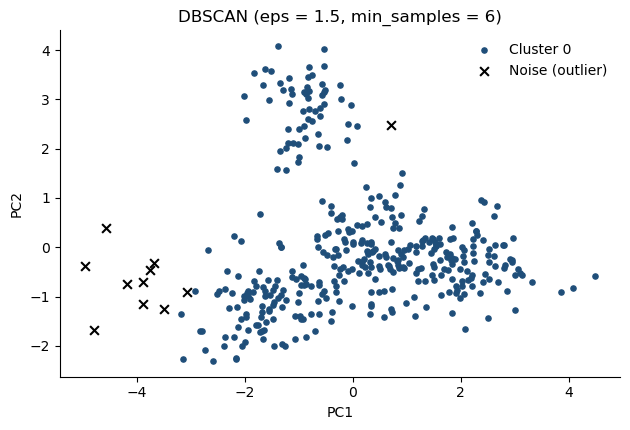

,household_id,area,avg_daily_kwh,daytime_share,evening_share,night_share
22,PH023,Kothrud,45.47,0.31,0.22,0.10
25,PH026,Hadapsar,32.65,0.38,0.27,0.13
30,PH031,Aundh,32.48,0.51,0.20,0.12
68,PH069,Warje,32.04,0.35,0.25,0.14
159,PH160,Warje,37.23,0.37,0.19,0.20
227,PH228,Aundh,39.03,0.34,0.27,0.14
248,PH249,Baner,22.68,0.11,0.52,0.26
324,PH325,Kothrud,34.65,0.32,0.21,0.23
355,PH356,Kothrud,46.71,0.29,0.23,0.20
365,PH366,Kondhwa,47.58,0.42,0.21,0.16


In [17]:
db = DBSCAN(eps=1.5, min_samples=MIN_PTS).fit(X)
lab_db = order_labels(db.labels_)
print("Clusters:", len(set(lab_db) - {-1}), " Noise points:", (lab_db == -1).sum())
plt.figure(figsize=(6.4, 4.4))
plt.scatter(P[lab_db != -1, 0], P[lab_db != -1, 1], s=14, color=PAL[0], label="Cluster 0")
plt.scatter(P[lab_db == -1, 0], P[lab_db == -1, 1], s=40, marker="x", color="black", label="Noise (outlier)")
plt.legend(frameon=False); plt.title("DBSCAN (eps = 1.5, min_samples = 6)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.show()
df[lab_db == -1][["household_id", "area", "avg_daily_kwh", "daytime_share", "evening_share", "night_share"]].round(2)

**Observation:** DBSCAN finds the unusual high-consumption households (outliers) very well, but joins the four normal household types into one cluster – they overlap and have no empty gaps between them. DBSCAN is a good **outlier detector** here, not a good **segmentation tool**.

## 8. Gaussian Mixture Model (distribution-based)
Assumes the data comes from a mixture of Gaussian distributions; learned with the EM algorithm. Gives **soft assignment** (probability of each cluster).

In [18]:
gmm = GaussianMixture(K, covariance_type="full", n_init=5, random_state=SEED).fit(X)
lab_g = order_labels(gmm.predict(X))
prob = gmm.predict_proba(X)
print("BIC:", round(gmm.bic(X), 1), " Silhouette:", round(silhouette_score(X, lab_g), 3), " DBI:", round(davies_bouldin_score(X, lab_g), 3))
print("Households with max membership probability < 0.8 (lie between two groups):", int((prob.max(1) < 0.8).sum()))
pd.DataFrame(prob[:5].round(2), columns=[f"P(comp {i})" for i in range(K)]).assign(household=df["household_id"][:5].values).set_index("household")

BIC: 4909.7  Silhouette: 0.295  DBI: 1.041
Households with max membership probability < 0.8 (lie between two groups): 19


,P(comp 0),P(comp 1),P(comp 2),P(comp 3)
household,,,,
PH001,0.0,0.0,0.0,1.0
PH002,1.0,0.0,0.0,0.0
PH003,0.0,0.0,1.0,0.0
PH004,0.0,0.0,0.0,1.0
PH005,0.0,0.0,1.0,0.0


## 9. Compare all algorithms

In [19]:
def metrics(name, lab):
    m = lab != -1; n_cl = len(set(lab[m]))
    row = {"Algorithm": name, "Clusters": n_cl, "Noise": int((~m).sum()), "ARI vs hidden groups": adjusted_rand_score(truth, lab)}
    if n_cl > 1:
        row.update({"Silhouette": silhouette_score(X[m], lab[m]), "Davies-Bouldin (lower)": davies_bouldin_score(X[m], lab[m]),
                    "Calinski-Harabasz (higher)": calinski_harabasz_score(X[m], lab[m])})
    return row
cmp = pd.DataFrame([metrics("K-Means", lab_km), metrics("Hierarchical (Ward)", lab_h), metrics("DBSCAN", lab_db), metrics("GMM", lab_g)]).set_index("Algorithm")
cmp.round(3)

,Clusters,Noise,ARI vs hidden groups,Silhouette,Davies-Bouldin (lower),Calinski-Harabasz (higher)
Algorithm,,,,,,
K-Means,4,0,0.782,0.305,1.118,244.671
Hierarchical (Ward),4,0,0.735,0.278,1.191,233.079
DBSCAN,1,11,0.035,NaN,NaN,NaN
GMM,4,0,0.571,0.295,1.041,172.143


In [20]:
print("K-Means clusters vs hidden lifestyle patterns (A, B, C, D = household types, X = unusual households):")
pd.crosstab(df["cluster"], df["true_segment"])

K-Means clusters vs hidden lifestyle patterns (A, B, C, D = household types, X = unusual households):


true_segment,A,B,C,D,X
cluster,,,,,
0,92,8,0,0,0
1,13,113,0,2,0
2,0,4,0,98,10
3,0,0,60,0,0


Note that **all 10 unusual (X) households were forced into cluster C2** by K-Means, because K-Means has no notion of noise. In practice, remove the DBSCAN outliers first, then run K-Means.

## 10. Summary
* K-Means (k = 4) gave the best overall result: silhouette ≈ 0.30, ARI ≈ 0.78 – four meaningful household types.
* Ward hierarchical clustering was close; the dendrogram supports a small number of clusters.
* DBSCAN detected all 10 unusual households but did not separate the normal types.
* GMM shows which households lie between two groups (soft membership).
* Silhouette ≈ 0.3 means *weak but present* structure – household types overlap, which is realistic.